# 日内波动、分钟数据质量与现役模型增量方案

本卡只回答三个问题：现有分钟数据是否完整，日内风险集中在哪些时段，以及这些信息应进入现有模型的哪个决策层。原生 Qlib 分钟读取是统计入口；raw 只用于数据资格审计与 store 构建。无模型拟合、回测、生产切换或订单。历史窗口全部是复用诊断，不是新样本外。

先冻结 `plan.json`；不完整日、OHLC 异常日与半日市不进入完整常规交易日的配对波动统计。半日市保留在质量审计里，不视为缺数据。补采快照独立保存在 Recorder，不自动覆盖 canonical。

官方依据：[Qlib Data](https://qlib.readthedocs.io/en/latest/component/data.html)、[Qlib Recorder](https://qlib.readthedocs.io/en/latest/component/recorder.html)、[富途历史 K 线](https://openapi.futunn.com/futu-api-doc/quote/request-history-kline.html)、[实时分钟推送](https://openapi.futunn.com/futu-api-doc/quote/update-kl.html)、[NYSE 交易时段](https://www.nyse.com/trade/hours-calendars)。

In [1]:
import os, sys, json, hashlib, logging, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import exchange_calendars as xc
from IPython.display import display
root = Path.cwd().resolve()
while not (root / "AGENTS.md").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
import qlib
from qlib.data import D
from qlib.workflow import R
from src.data import QlibProviderConfig, build_qlib_store_from_frame, load_qlib_feature_frame
from src.data.intraday import read_intraday_cache
from src.data.intraday_quality import audit_minute_coverage, plan_minute_repairs
from src.analysis.intraday_volatility import minute_volatility_reports
from src.data.provider_content_hash import provider_content_hash
for name in ["qlib", "mlflow"]:
    logging.getLogger(name).setLevel(logging.ERROR)
card = root / "research" / "intraday_volatility_data_diagnosis_20261012"
plan = json.loads((card / "plan.json").read_text())
source = root / plan["source"]
assert hashlib.sha256(source.read_bytes()).hexdigest() == plan["source_sha256"], "blocked: source snapshot changed"
minute = read_intraday_cache(source)
release = json.loads((root / "production/stage1_futu_sim_v1/runtime_release.json").read_text())
assert hashlib.sha256((root / "production/stage1_futu_sim_v1/runtime_release.json").read_bytes()).hexdigest() == plan["parent_release_sha256"], "blocked: active release changed"
assert release["release_id"] == plan["suggested_bounded_comparison"]["frozen_parent_release"]
print("source rows", len(minute), "as_of", plan["as_of"], "active release", release["release_id"])


2026/10/12 14:26:01 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/rziiiii/dev/workspace/qlib_venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


source rows 1518062 as_of 2026-10-09 active release stage1_hold_net_fees_20260928_paper_trial_v1


## 1. 分钟资格审计

审计使用显式交易所开闭市时点，并和项目日线 Qlib calendar 比对。`right_edge` 是仓库实际观测到的 09:31–16:00 时间约定；富途文档只说明美东时区，并未保证 bar 的收到时间。真正的因果特征还需 `received_at <= decision_at`，不能把 bar 标签视为采集延迟认证。

成交额/成交量计算的 VWAP 偏离 OHLC 是**价格口径问题的诊断**；这里不推断复权因子、不自动修复成交额。零量 bar 不构成缺口。

In [2]:
start = minute.timestamp.min().strftime("%Y-%m-%d")
exchange = xc.get_calendar("XNYS", start=start, end=plan["as_of"])
schedule = exchange.schedule[["open", "close"]].copy()
qlib.init(provider_uri=str(root / "data/qlib/soxl"), region="us", kernels=1)
daily_calendar = pd.DatetimeIndex(D.calendar(start_time=start, end_time=plan["as_of"], freq="day")).normalize()
calendar_comparison = {"exchange_calendar_version": xc.__version__, "exchange_sessions": len(schedule),
    "qlib_daily_sessions": len(daily_calendar),
    "exchange_only_dates": schedule.index.difference(daily_calendar).strftime("%Y-%m-%d").tolist(),
    "qlib_only_dates": daily_calendar.difference(schedule.index).strftime("%Y-%m-%d").tolist()}
coverage = audit_minute_coverage(minute, schedule, symbols=plan["symbols"],
    timestamp_convention=plan["timestamp_convention"], observed_at=pd.Timestamp(plan["observed_at"]))
repairs = plan_minute_repairs(coverage)
anomalies = coverage.loc[coverage.repair_required].copy()
coverage_summary = coverage.groupby("symbol").agg(expected_sessions=("date", "size"),
    complete_sessions=("training_eligible", "sum"), missing_minutes=("missing_minutes", "sum"),
    invalid_rows=("invalid_rows", "sum"), zero_volume_rows=("zero_volume_rows", "sum"),
    vwap_checked_rows=("vwap_checked_rows", "sum"), vwap_outside_rows=("vwap_outside_rows", "sum")).reset_index()
coverage_summary["vwap_outside_fraction"] = coverage_summary.vwap_outside_rows / coverage_summary.vwap_checked_rows
print(calendar_comparison)
display(coverage_summary, anomalies[["symbol", "date", "expected_minutes", "observed_minutes", "missing_minutes", "invalid_rows"]])


[71901:MainThread](2026-10-12 14:26:02,468) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[71901:MainThread](2026-10-12 14:26:02,470) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[71901:MainThread](2026-10-12 14:26:02,470) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/Users/rziiiii/dev/workspace/data/qlib/soxl')}


{'exchange_calendar_version': '4.13.2', 'exchange_sessions': 1955, 'qlib_daily_sessions': 1955, 'exchange_only_dates': [], 'qlib_only_dates': []}


,symbol,expected_sessions,complete_sessions,missing_minutes,invalid_rows,zero_volume_rows,vwap_checked_rows,vwap_outside_rows,vwap_outside_fraction
0,SOXL,1955,1953,719,0,1908,757123,624018,0.824196
1,SOXX,1955,1952,719,1,3444,755587,674785,0.893061


,symbol,date,expected_minutes,observed_minutes,missing_minutes,invalid_rows
607,SOXX,2020-03-16,390,390,0,1
3802,SOXL,2026-07-27,390,61,329,0
3803,SOXX,2026-07-27,390,61,329,0
3806,SOXL,2026-07-29,390,0,390,0
3807,SOXX,2026-07-29,390,0,390,0


## 2. 原生 Qlib 1 分钟 store 与配对波动

临时 store 位于仓库外，通过现有 `src/data` builder 生成、Qlib calendar/instruments/features 读回并登记 manifest。它不改写生产 5/15 分钟 store。统计代码拒绝不带 Qlib Data API 身份的输入；只用价格和成交量，不使用未经口径认证的 turnover/VWAP。

日内实现方差是分钟 log-return 平方和，首分钟从开盘价计算。时间分段是预登记的 `(左端, 右端]`；先按交易日计算方差/成交量占比再求均值，避免少数极端日决定全样本比例。1m/5m 方差比由相同分钟路径计算，仅描述频率敏感性，不能视为择时收益。

In [3]:
scratch = tempfile.TemporaryDirectory(prefix="soxl-minute-diagnosis-")
provider = Path(scratch.name) / "qlib_1min"
store_input = minute.rename(columns={"symbol": "instrument", "timestamp": "datetime"}).copy()
fields = ["open", "high", "low", "close", "volume"]
manifest = build_qlib_store_from_frame(store_input, provider_uri=provider, region="us", market="all", freq="1min",
    field_map={"$" + name: name for name in fields}, as_of=plan["as_of"],
    source=plan["source"] + " sha256=" + plan["source_sha256"])
features = load_qlib_feature_frame(QlibProviderConfig(provider, freq="1min"), instruments=plan["symbols"],
    fields=["$" + name for name in fields], start=manifest["calendar_start"], end=manifest["calendar_end"])
provider_digest, provider_inventory = provider_content_hash(provider)
manifest["content_sha256"] = provider_digest
manifest["content_inventory"] = provider_inventory
reports = minute_volatility_reports(features, coverage, segments=[tuple(s) for s in plan["segments"]])
daily, profile, annual = reports["daily"], reports["profile"], reports["annual"]
window_rows = []
for name, left, right in [("development_reused", "2019-01-01", "2022-12-31"),
    ("later_reused_diagnostic", "2023-01-01", plan["as_of"]), ("last_20_complete", None, None)]:
    for symbol, rows in daily.groupby("instrument"):
        rows = rows.tail(20) if left is None else rows.loc[rows.date.between(left, right)]
        window_rows.append(dict(window=name, instrument=symbol, sessions=len(rows),
            start=rows.date.min(), end=rows.date.max(), median_realized_vol_pct=rows.realized_vol_pct.median(),
            p90_realized_vol_pct=rows.realized_vol_pct.quantile(0.9), median_range_pct=rows.range_pct.median(),
            median_rv1_to_rv5_ratio=rows.rv1_to_rv5_ratio.median()))
windows = pd.DataFrame(window_rows)
parts = reports["segment_daily"]
information = []
for symbol, rows in parts.groupby("instrument"):
    opening = rows.loc[rows.segment.isin(["09:30-10:00", "10:00-10:30"])].groupby("date").agg(
        early_rv=("rv", "sum"), early_open=("opening", "first"), early_close=("closing", "last"))
    remaining = rows.loc[~rows.segment.isin(["09:30-10:00", "10:00-10:30"])].groupby("date").agg(
        later_rv=("rv", "sum"), later_open=("opening", "first"), later_close=("closing", "last"))
    joined = opening.join(remaining)
    joined["early_return"] = joined.early_close / joined.early_open - 1
    joined["later_return"] = joined.later_close / joined.later_open - 1
    for name, left, right in [("development_reused", "2019-01-01", "2022-12-31"),
        ("later_reused_diagnostic", "2023-01-01", plan["as_of"])]:
        sample = joined.loc[left:right]
        information.append(dict(instrument=symbol, window=name, sessions=len(sample),
            early_later_variance_rank_corr=sample.early_rv.corr(sample.later_rv, method="spearman"),
            early_later_return_rank_corr=sample.early_return.corr(sample.later_return, method="spearman"),
            interpretation="descriptive only; no model fit, no causal alpha or promotion inference"))
information = pd.DataFrame(information)
display(profile, annual, windows, information)


[71901:MainThread](2026-10-12 14:26:09,431) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[71901:MainThread](2026-10-12 14:26:09,432) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[71901:MainThread](2026-10-12 14:26:09,432) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/private/var/folders/4n/bc8v7c391nq228754jxg84_w0000gn/T/soxl-minute-diagnosis-wrdujkph/qlib_1min')}


[71901:MainThread](2026-10-12 14:26:09,791) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[71901:MainThread](2026-10-12 14:26:09,792) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


...

[71901:MainThread](2026-10-12 14:26:12,315) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/private/var/folders/4n/bc8v7c391nq228754jxg84_w0000gn/T/soxl-minute-diagnosis-wrdujkph/qlib_1min')}


,instrument,segment,sessions,minutes,mean_variance_share,median_variance_share,mean_volume_share,median_vol_per_minute_bps
0,SOXL,09:30-10:00,1937,30,0.283831,0.278279,0.193003,39.292400
1,SOXX,09:30-10:00,1937,30,0.285644,0.279815,0.172549,13.144579
2,SOXL,10:00-10:30,1937,30,0.138123,0.131507,0.118869,27.714472
3,SOXX,10:00-10:30,1937,30,0.138910,0.131516,0.097781,9.128081
4,SOXL,10:30-12:00,1937,90,0.222194,0.214843,0.227659,20.185253
5,SOXX,10:30-12:00,1937,90,0.222646,0.216075,0.196736,6.735005
6,SOXL,12:00-14:00,1937,120,0.165850,0.154398,0.195371,15.056989
7,SOXX,12:00-14:00,1937,120,0.164256,0.153268,0.181832,4.987860
8,SOXL,14:00-15:30,1937,90,0.129971,0.107607,0.151496,14.455816
9,SOXX,14:00-15:30,1937,90,0.128100,0.106295,0.167220,4.813825


,instrument,year,sessions,median_realized_vol_pct,p90_realized_vol_pct,median_range_pct,median_rv1_to_rv5_ratio
0,SOXL,2018,1,4.948647,4.948647,5.577540,1.156617
1,SOXL,2019,249,3.153827,4.770450,4.860079,1.044641
2,SOXL,2020,250,4.080829,8.007895,6.375736,1.018603
3,SOXL,2021,251,3.657497,5.638413,6.013000,0.946293
4,SOXL,2022,250,5.813869,8.139961,9.635729,0.991762
5,SOXL,2023,248,3.929189,5.168064,6.347579,1.043383
6,SOXL,2024,249,4.030544,6.276147,6.414199,0.967098
7,SOXL,2025,247,4.098952,6.974392,6.214690,1.032632
8,SOXL,2026,192,5.457969,9.172680,8.546657,1.015551
9,SOXX,2018,1,1.701382,1.701382,1.833725,1.176465


,window,instrument,sessions,start,end,median_realized_vol_pct,p90_realized_vol_pct,median_range_pct,median_rv1_to_rv5_ratio
0,development_reused,SOXL,1000,2019-01-02,2022-12-30,4.146105,7.063479,6.658459,1.004232
1,development_reused,SOXX,1000,2019-01-02,2022-12-30,1.376035,2.327675,2.176958,1.007128
2,later_reused_diagnostic,SOXL,936,2023-01-03,2026-10-09,4.222025,6.865019,6.581247,1.014063
3,later_reused_diagnostic,SOXX,936,2023-01-03,2026-10-09,1.416523,2.259488,2.172482,1.012055
4,last_20_complete,SOXL,20,2026-09-14,2026-10-09,3.829451,5.547489,5.857521,1.007878
5,last_20_complete,SOXX,20,2026-09-14,2026-10-09,1.327407,1.781094,1.897109,0.991148


,instrument,window,sessions,early_later_variance_rank_corr,early_later_return_rank_corr,interpretation
0,SOXL,development_reused,1000,0.799190,0.086645,"descriptive only; no model fit, no causal alph..."
1,SOXL,later_reused_diagnostic,936,0.662930,0.040933,"descriptive only; no model fit, no causal alph..."
2,SOXX,development_reused,1000,0.800527,0.085755,"descriptive only; no model fit, no causal alph..."
3,SOXX,later_reused_diagnostic,936,0.676973,0.051576,"descriptive only; no model fit, no causal alph..."


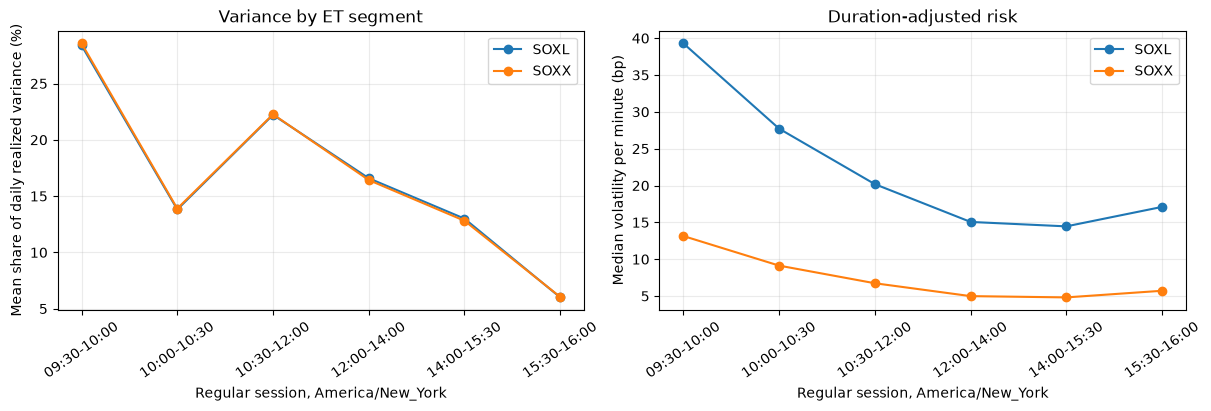

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
labels = [s[0] for s in plan["segments"]]
for symbol, group in profile.groupby("instrument"):
    indexed = group.set_index("segment").reindex(labels)
    axes[0].plot(labels, 100 * indexed.mean_variance_share, marker="o", label=symbol)
    axes[1].plot(labels, indexed.median_vol_per_minute_bps, marker="o", label=symbol)
axes[0].set(ylabel="Mean share of daily realized variance (%)", title="Variance by ET segment")
axes[1].set(ylabel="Median volatility per minute (bp)", title="Duration-adjusted risk")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.set_xlabel("Regular session, America/New_York")
    ax.grid(alpha=0.25)
    ax.legend()
fig.savefig(card / "intraday_volatility.png", dpi=150)
plt.show()


## 3. 采集补强与当前模型的连接

1. 采集端保留 `bar_start_at`、`bar_end_at`、`received_at`、`finalized_at`、时区、session、实际复权类型、复权版本及来源。盘中接收 `K_1M` 推送时区分临时 bar 和已结束 bar；历史接口用于重连及收盘后对账。先核查历史额度与权限，首页限频，分页断点续传，按 symbol/date 分区写入临时文件，校验后原子替换。
2. 用显式交易所日历检查每个 symbol/session 的 390 或 210 个预期分钟。修复队列覆盖历史缺分钟和整天缺失，不只看最新日期。5/15 分钟聚合同时写 `observed_1m_count`、`expected_1m_count`、`is_complete`、`available_at`，不把全日 `bar_count` 当覆盖率。现役采集器尚未接入本卡新审计器。
3. 原始不复权执行价格与研究复权价格分开存储。成交额/成交量、OHLC、VWAP 必须同一价格与量口径；目前不能直接使用历史 `turnover/volume`。补采快照仍待复权版本与成交量来源核验；覆盖率提高不等于价量合同通过。
4. 先增加 QQQ、SMH、NVDA、AMD 的同步常规分钟，研究窗口从实际共同可用期开始，不补造长期成分股历史。现有外部 15 分钟 provider 截止 2026-07-02，不能当当前分钟源。盘前/盘后另外标记和建模，其短历史不与 8 年常规分钟混为一谈。
5. 保持当前 MLP 分配层和 Logistic 执行/恢复层的身份。开盘 09:31 只能用昨日完整分钟；10:31 恢复可以用 10:30 前已收到并结束的分钟。先用三个小特征：首小时 RV、下行半方差占比、趋势效率；之后才做同步市场上下文对照。分钟量异常只在来源和时段标准化合同通过后加入。
6. 模型方案仅为预算 3 的提案，见 `plan.json`：原模型、增加分钟风险、再增加同步市场上下文。训练保持自身状态的成熟净执行优势标签，10/25bp 分别生成账户与路径；选择只看 development。早晚波动相关性只能说明风险持续性，不能代替超额证据；历史复用、低换手和风险统计都不签发晋升。

In [5]:
tracking = card / "qlib_recorder"
# On first execution consume the explicit read-only probes. On rerun retrieve
# these already archived bytes through the existing child Recorder, never refetch.
probe_dir = Path("/tmp/soxl-intraday-20261012")
if (card / "summary.json").exists():
    previous = json.loads((card / "summary.json").read_text())
    with R.uri_context(str(tracking)):
        prior = R.get_recorder(recorder_id=previous["recorder_id"], experiment_id=previous["experiment_id"])
        repair_candidates = prior.load_object("inputs/repair_candidates")
        overlap = prior.load_object("inputs/probe_overlap")
        probe_metadata = prior.load_object("inputs/probe_metadata")
else:
    repair_candidates = pd.read_parquet(probe_dir / "repair_candidates.parquet")
    overlap = json.loads((probe_dir / "overlaps.json").read_text())
    probe_metadata = json.loads((probe_dir / "probe_metadata.json").read_text())
    probe_metadata["requests"] += [{"symbol": row["symbol"], "date": row["date"], "rows": row["rows"],
        "ret": 0, "more_pages": False} for row in overlap if row["date"] == "2026-07-27"]
action_summary = json.loads((root / release["action"]["card_path"] / "summary.json").read_text())
action_diagnosis = json.loads((root / "research/stage1_action_marginal_diagnosis_20261009/summary.json").read_text())
recorder_only = ["inputs/coverage", "inputs/exchange_schedule", "inputs/repair_candidates",
    "inputs/probe_overlap", "inputs/probe_metadata", "inputs/store_manifest", "inputs/plan",
    "analysis/daily", "analysis/segment_daily", "analysis/residual", "analysis/summary"]
summary = {"experiment": plan["experiment"], "schema_version": plan["schema_version"],
    "card_status": "completed_descriptive_diagnosis", "decision": "data_repairs_need_basis_validation_model_comparison_proposed",
    "promotion_eligible": False, "objective_achieved": False, "model_fits": 0, "backtests": 0,
    "provider_uri": str(provider), "provider_lifecycle": "temporary_rebuilt_from_hash_pinned_canonical_snapshot",
    "provider_content_sha256": provider_digest, "market": "all", "region": "us", "freq": "1min", "as_of": plan["as_of"],
    "parent_release_sha256": plan["parent_release_sha256"],
    "context_sources": {str(path.relative_to(root)): hashlib.sha256(path.read_bytes()).hexdigest() for path in [root / release["action"]["card_path"] / "summary.json", root / "research/stage1_action_marginal_diagnosis_20261009/summary.json"]},
    "source": plan["source"], "source_sha256": plan["source_sha256"], "source_rows": len(minute),
    "calendar_comparison": calendar_comparison, "coverage": coverage_summary.to_dict("records"),
    "paired_full_regular_sessions": daily.date.nunique(), "half_sessions": int(coverage.expected_minutes.eq(210).sum()/2),
    "repair_plan": repairs.to_dict("records"), "repairs_admitted": False, "probe_overlap": overlap,
    "active_release": release, "action_development_gate_pass": action_summary["development_gate_pass"],
    "active_action_information": action_diagnosis["conditional_information"],
    "profile": profile.to_dict("records"), "annual": annual.to_dict("records"),
    "windows": windows.to_dict("records"), "descriptive_information": information.to_dict("records"),
    "artifact_policy": {"policy": "slim_card_recorder_first", "workflow_config": "workflow.yaml",
        "recorder_only_artifacts": recorder_only},
    "qlib_docs_reference": ["https://qlib.readthedocs.io/en/latest/component/data.html", "https://qlib.readthedocs.io/en/latest/component/recorder.html"],
    "limitations": ["All historical windows are reused descriptive diagnostics, not fresh OOS or forward evidence.",
        "No signal, fitted candidate, native portfolio backtest or production promotion was created.",
        "Minute stamps are observed right edges; first-public/received_at and live finalization are not certified.",
        "Turnover-derived VWAP basis is unqualified; repair snapshots are quarantined.",
        "Source updates were existing uncommitted WIP; source hash is pinned and no upstream WIP is committed.",
        "Shared collectors and active paper/SIM behavior were not changed."]}
with R.start(experiment_name=plan["experiment"], recorder_name="minute_volatility_diagnosis", uri=str(tracking)):
    recorder = R.get_recorder()
    recorder.log_params(source_sha256=plan["source_sha256"], as_of=plan["as_of"], model_fits=0,
        provider_uri=str(provider), timestamp_convention=plan["timestamp_convention"])
    recorder.save_objects(artifact_path="inputs", coverage=coverage, exchange_schedule=schedule,
        repair_candidates=repair_candidates, probe_overlap=overlap, probe_metadata=probe_metadata,
        store_manifest=manifest, plan=plan)
    recorder.save_objects(artifact_path="analysis", daily=daily, segment_daily=reports["segment_daily"],
        residual=reports["residual"], summary=summary)
    recorder.log_metrics(paired_full_sessions=daily.date.nunique(), missing_minutes=int(coverage.missing_minutes.sum()),
        invalid_rows=int(coverage.invalid_rows.sum()), registered_artifact_count=len(recorder_only))
    identity = {"recorder_id": recorder.id, "experiment_id": str(recorder.experiment_id),
        "recorder_uri": str(tracking), "recorder_local_dir": str(tracking / str(recorder.experiment_id) / recorder.id)}
summary.update(identity)
recorder.save_objects(artifact_path="analysis", summary=summary)
(card / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + "\n")
for name, table in {"coverage_summary": coverage_summary, "coverage_anomalies": anomalies,
    "repair_plan": repairs, "intraday_profile": profile, "regime_metrics": annual,
    "window_metrics": windows, "descriptive_information": information}.items():
    table.to_csv(card / (name + ".csv"), index=False)
import yaml
(card / "workflow.yaml").write_text(yaml.safe_dump({"experiment": plan["experiment"],
    "provider_uri": str(provider), "provider_rebuild_source": plan["source"], "source_sha256": plan["source_sha256"],
    "region": "us", "market": "all", "freq": "1min", "as_of": plan["as_of"],
    "recorder_uri": str(tracking), "model_selection": "none_descriptive_diagnosis",
    "artifact_policy": summary["artifact_policy"]}, allow_unicode=True, sort_keys=False))
selected = {"model_selection": "none_descriptive_diagnosis", "current_parent_release": release["release_id"],
    "current_allocation_recorder": release["allocation"]["recorder_id"], "current_action_recorder": release["action"]["recorder_id"],
    "candidate_comparison": "proposed_not_executed", "production_enabled": False}
(card / "selected_model.json").write_text(json.dumps(selected, indent=2) + "\n")
# Required self-contained Chinese conclusion, synchronized from executed metrics.
opening = profile.loc[profile.segment.eq("09:30-10:00")].set_index("instrument")
soxl_years = annual.loc[annual.instrument.eq("SOXL")].set_index("year")
conclusion = f"""# 中文结论

本次执行原生 Qlib 1 分钟 store 构建、D.calendar/D.instruments/D.features 读回、分钟资格审计和分时波动统计；没有拟合模型、回测策略或改变现役运行。

- 源数据：{len(minute):,} 行，{start} 至 {plan["as_of"]}；逐日显式预期 {len(schedule)} 个交易日/标的。完整常规且两标的均通过价量基本检查的配对统计为 {daily.date.nunique()} 日；另有 {summary["half_sessions"]} 个正常半日市。
- 缺口：2026-07-27 每标的缺 329 分钟，2026-07-29 每标的整日缺 390 分钟；SOXX 2020-03-16 首分钟 OHLC 不一致，排除该配对日。
- 分时：开盘后 30 分钟平均贡献 SOXL 日内实现方差 {100*opening.loc["SOXL", "mean_variance_share"]:.2f}%、SOXX {100*opening.loc["SOXX", "mean_variance_share"]:.2f}%；该时段仅占常规交易日 7.69%。这是风险集中度，不是可交易收益。
- 年度/窗口差异：SOXL 2020 年日内 RV 中位数 {soxl_years.loc[2020, "median_realized_vol_pct"]:.2f}%，2026 年 {soxl_years.loc[2026, "median_realized_vol_pct"]:.2f}%；更多年份和最近 20 个完整交易日见 regime_metrics.csv/window_metrics.csv，全部是复用诊断。
- 数据风险：成交额/成交量 VWAP 偏离 OHLC 的比例约 {100*coverage.vwap_outside_rows.sum()/len(minute):.2f}%（按全部记录计；容差 0.1%）。不能直接将它作为复权价 VWAP 因子。补采共 {len(repair_candidates)} 行已在 Recorder 独立保存，但重叠价格和成交量变化尚未解释，未合入 canonical。
- 当前模型：绑定 allocation {release["allocation"]["recorder_id"]}、action {release["action"]["recorder_id"]}；action development gate 为 false。可决策样本历史 AUC 为 {action_diagnosis["conditional_information"]["auc"]:.4f}，区间包含 0.5；分钟风险增量尚未验证。
- 晋升：本卡为 completed_descriptive_diagnosis，promotion_eligible=false、objective_achieved=false。风险持续性相关或数据补齐都不证明稳定跑赢 SOXX。
- 下一步：把显式缺口审计接入独立采集管道，核验复权/成交量来源，保存 received_at/finalized_at；再按 plan.json 的最多 3 个对照检验首小时 RV、下行半方差、趋势效率。09:31 仅用昨日分钟，10:31 仅用 10:30 前已收到并结束的分钟；10/25bp 各自生成完整账户和成熟净执行优势标签，development 选择，独立前向决定晋升。
- Qlib Recorder：{identity["recorder_id"]}；大表和独立补采快照仅在 Recorder，根目录保持小摘要、主 notebook、图和结论。
"""
(card / "conclusion.md").write_text(conclusion)
# Store a content manifest for every Recorder artifact that is committed.
artifact_dir = Path(identity["recorder_local_dir"]) / "artifacts"
entries = [{"path": str(p.relative_to(card)), "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
    "bytes": p.stat().st_size} for p in sorted(artifact_dir.rglob("*")) if p.is_file() and not p.name.startswith("code_")]
(card / "verification_manifest.json").write_text(json.dumps({"recorder_id": identity["recorder_id"],
    "source_sha256": plan["source_sha256"], "entries": entries}, indent=2) + "\n")
scratch.cleanup()
print("Recorder", identity["recorder_id"], "registered artifacts", len(entries))


[71901:MainThread](2026-10-12 14:26:15,703) WARNING - qlib.workflow - [expm.py:231] - No valid experiment found. Create a new experiment with name intraday_volatility_data_diagnosis_20261012.


[71901:MainThread](2026-10-12 14:26:15,705) INFO - qlib.workflow - [exp.py:258] - Experiment 352113610922857045 starts running ...


[71901:MainThread](2026-10-12 14:26:15,792) INFO - qlib.workflow - [recorder.py:345] - Recorder 70ec0bf081df4ec9b6bc47dd2e621ba9 starts running under Experiment 352113610922857045 ...


[71901:MainThread](2026-10-12 14:26:16,686) INFO - qlib.timer - [log.py:127] - Time cost: 0.001s | waiting `async_log` Done


Recorder 70ec0bf081df4ec9b6bc47dd2e621ba9 registered artifacts 11


## 最终中文结论

执行后的最终结论从 `conclusion.md` 原样显示，保证 notebook 与 sidecar 指标一致。

In [6]:
from IPython.display import Markdown
assert not summary["promotion_eligible"] and summary["model_fits"] == 0
display(Markdown((card / "conclusion.md").read_text()))

# 中文结论

本次执行原生 Qlib 1 分钟 store 构建、D.calendar/D.instruments/D.features 读回、分钟资格审计和分时波动统计；没有拟合模型、回测策略或改变现役运行。

- 源数据：1,518,062 行，2018-12-31 至 2026-10-09；逐日显式预期 1955 个交易日/标的。完整常规且两标的均通过价量基本检查的配对统计为 1937 日；另有 15 个正常半日市。
- 缺口：2026-07-27 每标的缺 329 分钟，2026-07-29 每标的整日缺 390 分钟；SOXX 2020-03-16 首分钟 OHLC 不一致，排除该配对日。
- 分时：开盘后 30 分钟平均贡献 SOXL 日内实现方差 28.38%、SOXX 28.56%；该时段仅占常规交易日 7.69%。这是风险集中度，不是可交易收益。
- 年度/窗口差异：SOXL 2020 年日内 RV 中位数 4.08%，2026 年 5.46%；更多年份和最近 20 个完整交易日见 regime_metrics.csv/window_metrics.csv，全部是复用诊断。
- 数据风险：成交额/成交量 VWAP 偏离 OHLC 的比例约 85.56%（按全部记录计；容差 0.1%）。不能直接将它作为复权价 VWAP 因子。补采共 1560 行已在 Recorder 独立保存，但重叠价格和成交量变化尚未解释，未合入 canonical。
- 当前模型：绑定 allocation f696f656b3d44e868588e09a5d97c905、action b472a458fc9042b4905094fddeaebd33；action development gate 为 false。可决策样本历史 AUC 为 0.5168，区间包含 0.5；分钟风险增量尚未验证。
- 晋升：本卡为 completed_descriptive_diagnosis，promotion_eligible=false、objective_achieved=false。风险持续性相关或数据补齐都不证明稳定跑赢 SOXX。
- 下一步：把显式缺口审计接入独立采集管道，核验复权/成交量来源，保存 received_at/finalized_at；再按 plan.json 的最多 3 个对照检验首小时 RV、下行半方差、趋势效率。09:31 仅用昨日分钟，10:31 仅用 10:30 前已收到并结束的分钟；10/25bp 各自生成完整账户和成熟净执行优势标签，development 选择，独立前向决定晋升。
- Qlib Recorder：70ec0bf081df4ec9b6bc47dd2e621ba9；大表和独立补采快照仅在 Recorder，根目录保持小摘要、主 notebook、图和结论。
